# Process Discovery Results Summary — BPI 2020 Travel Permit

This notebook summarizes the process-discovery experiment on the **BPI 2020 Travel Permit** event log (1000-case sample).

It follows the structure of the BPI 2019 summary notebook, adapted for a single dataset/sample size. It uses the reconstructed fitness column (`fitness_reconstructed`) and focuses on run validation, baseline behavior, degradation effects, model complexity, and trends across degradation levels.

## Questions addressed

1. Did all experimental runs finish successfully?
2. How do Alpha, Heuristics, and Inductive Miner behave on the baseline log?
3. Which degradation dimensions affect quality and model complexity the most?
4. How do the metrics change from 10% to 30% degradation?
5. Are there failed runs or other data-quality issues to account for when interpreting results?

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

# Works when opened from the project root or from a notebooks/ folder.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "experiments").exists() and (PROJECT_ROOT.parent / "experiments").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Update this path if your repository stores the results elsewhere.
RESULTS_PATH = (
    PROJECT_ROOT
    / "experiments"
    / "process_discovery"
    / "results"
    / "bpi2020_travel_permit_1000"
    / "metrics"
    / "discovery_results_with_fitness.csv"
)

FIGURES_DIR = (
    PROJECT_ROOT
    / "experiments"
    / "process_discovery"
    / "results"
    / "figures"
    / "bpi2020_travel_permit_summary"
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Results file:", RESULTS_PATH)
print("Figures directory:", FIGURES_DIR)

Project root: C:\Users\User\Desktop\projects\thesis-discovery\Data-Quality-Impact-on-Process-Discovery
Results file: C:\Users\User\Desktop\projects\thesis-discovery\Data-Quality-Impact-on-Process-Discovery\experiments\process_discovery\results\bpi2020_travel_permit_1000\metrics\discovery_results_with_fitness.csv
Figures directory: C:\Users\User\Desktop\projects\thesis-discovery\Data-Quality-Impact-on-Process-Discovery\experiments\process_discovery\results\figures\bpi2020_travel_permit_summary


## 1. Load and validate results

The original `fitness` field was not directly stored as a flat numeric value. This notebook therefore uses `fitness_reconstructed` as the fitness metric. Failed runs are kept in the run-validation table, but excluded from metric summaries.

In [2]:
QUALITY_METRICS = [
    "fitness",
    "precision",
    "generalization",
    "simplicity",
    "average_score",
]

STRUCTURAL_METRICS = [
    "places",
    "transitions",
    "visible_transitions",
    "hidden_transitions",
    "arcs",
    "activities_after",
]

DIMENSIONS = ["accuracy", "completeness", "consistency", "timeliness"]
MINERS = ["alpha", "heuristics", "inductive"]


def load_results(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(
            f"Results file not found: {path}\n"
            "Update RESULTS_PATH in the setup cell to point to the BPI 2020 "
            "discovery_results_with_fitness.csv file."
        )

    data = pd.read_csv(path)

    required = {"dimension", "degradation_level", "repetition", "miner", "status"}
    missing = required - set(data.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    if "fitness_reconstructed" not in data.columns:
        raise ValueError(
            "The file must contain 'fitness_reconstructed'. "
            "Use the reconstructed-fitness results CSV."
        )

    data["fitness"] = pd.to_numeric(data["fitness_reconstructed"], errors="coerce")

    numeric_cols = [
        "degradation_level",
        "repetition",
        *QUALITY_METRICS,
        *STRUCTURAL_METRICS,
    ]
    for col in numeric_cols:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors="coerce")

    return data


raw_df = load_results(RESULTS_PATH)
successful_df = raw_df[raw_df["status"].eq("ok")].copy()
failed_df = raw_df[~raw_df["status"].eq("ok")].copy()

run_summary = pd.DataFrame([{
    "total_runs": len(raw_df),
    "successful_runs": len(successful_df),
    "failed_runs": len(failed_df),
    "success_rate_pct": 100 * len(successful_df) / len(raw_df) if len(raw_df) else np.nan,
    "miners": raw_df["miner"].nunique(),
    "dimensions_including_baseline": raw_df["dimension"].nunique(),
    "repetitions_max": raw_df["repetition"].max(),
}])

display(run_summary)
display(
    raw_df.groupby(["dimension", "degradation_level", "status"], dropna=False)
    .size()
    .rename("runs")
    .reset_index()
    .sort_values(["dimension", "degradation_level", "status"])
)

,total_runs,successful_runs,failed_runs,success_rate_pct,miners,dimensions_including_baseline,repetitions_max
0,183,181,2,98.907104,3,5,5


,dimension,degradation_level,status,runs
0,accuracy,10,ok,15
1,accuracy,20,ok,15
2,accuracy,30,ok,15
3,baseline,0,ok,3
4,completeness,10,ok,15
5,completeness,20,ok,15
6,completeness,30,ok,15
7,consistency,10,ok,15
8,consistency,20,ok,15
9,consistency,30,failed,2


In [3]:
# Inspect failed runs and error messages, if any.
if failed_df.empty:
    print("All runs completed successfully.")
else:
    display(
        failed_df[
            [c for c in [
                "dimension", "degradation_level", "repetition", "miner", "status", "error"
            ] if c in failed_df.columns]
        ].sort_values(["dimension", "degradation_level", "miner", "repetition"])
    )

# Check reconstructed fitness and other quality metrics for missing or out-of-range values.
quality_validation_rows = []
for metric in QUALITY_METRICS:
    if metric not in successful_df.columns:
        continue
    values = successful_df[metric].dropna()
    quality_validation_rows.append({
        "metric": metric,
        "missing_values": int(successful_df[metric].isna().sum()),
        "min": values.min() if len(values) else np.nan,
        "max": values.max() if len(values) else np.nan,
        "outside_0_1": int(((values < 0) | (values > 1)).sum()) if metric in QUALITY_METRICS else np.nan,
    })

quality_validation = pd.DataFrame(quality_validation_rows)
display(quality_validation.round(4))

,dimension,degradation_level,repetition,miner,status,error
128,consistency,30,2,inductive,failed,RecursionError('maximum recursion depth exceed...
131,consistency,30,3,inductive,failed,RecursionError('maximum recursion depth exceed...


,metric,missing_values,min,max,outside_0_1
0,fitness,0,0.1107,1.0000,0
1,precision,0,0.0437,1.0000,0
2,generalization,0,0.3650,0.9218,0
3,simplicity,0,0.1759,1.0000,0
4,average_score,0,0.2634,0.7250,0


### Interpretation of failed runs

The two failed executions are both for `inductive`, `consistency`, at 30% degradation (repetitions 2 and 3), with `RecursionError`. Keep these rows in the source results file for traceability, but exclude them from metric aggregates because they did not produce valid metric values. The corresponding condition therefore has three successful repetitions instead of five. The metric validation table above reports no missing values and no values outside [0, 1] for the checked quality metrics.

## 2. Baseline comparison

This table compares the three miners on the non-degraded baseline log. These are descriptive averages; they should not be interpreted as statistical significance tests.

In [4]:
baseline_df = successful_df[successful_df["dimension"].eq("baseline")].copy()

baseline_metrics = [m for m in QUALITY_METRICS + ["places", "transitions", "arcs"] if m in baseline_df.columns]
baseline_table = (
    baseline_df.groupby("miner", as_index=False)[baseline_metrics]
    .mean()
    .sort_values("miner")
)

display(baseline_table.round(3))

,miner,fitness,precision,generalization,simplicity,average_score,places,transitions,arcs
0,alpha,0.448,0.062,0.794,0.281,0.396,66.0,45.0,253.0
1,heuristics,0.821,0.875,0.538,0.512,0.687,82.0,153.0,347.0
2,inductive,1.000,0.114,0.834,0.602,0.638,103.0,163.0,354.0


## 3. Prepare aggregated results

Baseline values are copied to each degradation dimension at level 0 so the plots can show 0%, 10%, 20%, and 30% on the same axis. Degraded results are averaged over successful repetitions for each miner and condition.

In [5]:
def add_baseline_to_each_dimension(input_df: pd.DataFrame) -> pd.DataFrame:
    baseline_rows = input_df[input_df["dimension"].eq("baseline")].copy()
    degraded_rows = input_df[input_df["dimension"].ne("baseline")].copy()

    expanded = []
    for dimension in DIMENSIONS:
        temp = baseline_rows.copy()
        temp["dimension"] = dimension
        temp["degradation_level"] = 0
        temp["repetition"] = 0
        expanded.append(temp)

    expanded_baseline = pd.concat(expanded, ignore_index=True)
    return pd.concat([expanded_baseline, degraded_rows], ignore_index=True)


plot_ready_df = add_baseline_to_each_dimension(successful_df)

available_metrics = [m for m in QUALITY_METRICS + STRUCTURAL_METRICS if m in plot_ready_df.columns]
agg = (
    plot_ready_df
    .groupby(["dimension", "degradation_level", "miner"], as_index=False)[available_metrics]
    .mean()
)

display(agg.head(12).round(3))

,dimension,degradation_level,miner,fitness,precision,generalization,simplicity,average_score,places,transitions,visible_transitions,hidden_transitions,arcs,activities_after
0,accuracy,0,alpha,0.448,0.062,0.794,0.281,0.396,66.0,45.0,45.0,0.0,253.0,45.0
1,accuracy,0,heuristics,0.821,0.875,0.538,0.512,0.687,82.0,153.0,45.0,108.0,347.0,45.0
2,accuracy,0,inductive,1.000,0.114,0.834,0.602,0.638,103.0,163.0,45.0,118.0,354.0,45.0
3,accuracy,10,alpha,0.129,0.935,0.883,0.210,0.539,67.6,45.0,45.0,0.0,334.4,45.0
4,accuracy,10,heuristics,0.791,0.965,0.394,0.408,0.640,246.6,527.8,45.0,482.8,1335.6,45.0
5,accuracy,10,inductive,0.993,0.276,0.902,0.538,0.677,53.8,100.2,45.0,55.2,219.6,45.0
6,accuracy,20,alpha,0.128,1.000,0.902,0.234,0.566,50.4,45.0,45.0,0.0,255.4,45.0
7,accuracy,20,heuristics,0.753,0.964,0.397,0.378,0.623,374.6,733.4,45.0,688.4,2021.4,45.0
8,accuracy,20,inductive,1.000,0.187,0.910,0.511,0.652,45.2,90.6,45.0,45.6,200.4,45.0
9,accuracy,30,alpha,0.126,0.991,0.913,0.245,0.569,53.2,45.0,45.0,0.0,253.4,45.0


## 4. Effect at 30% degradation

For each dimension and miner, compare the mean metric at 30% degradation with that miner's baseline. The dimension-level table then averages these miner-specific effects. Percentage changes are omitted where the baseline denominator is zero or missing.

In [6]:
baseline_ref = (
    agg[agg["degradation_level"].eq(0)]
    [["dimension", "miner", "average_score", "arcs", "activities_after"]]
    .rename(columns={
        "average_score": "baseline_average_score",
        "arcs": "baseline_arcs",
        "activities_after": "baseline_activities",
    })
)

level_30 = agg[agg["degradation_level"].eq(30)].copy()
effects_30 = level_30.merge(baseline_ref, on=["dimension", "miner"], how="left")

effects_30["average_score_delta"] = (
    effects_30["average_score"] - effects_30["baseline_average_score"]
)
effects_30["arcs_pct_change"] = np.where(
    effects_30["baseline_arcs"].notna() & effects_30["baseline_arcs"].ne(0),
    100 * (effects_30["arcs"] - effects_30["baseline_arcs"]) / effects_30["baseline_arcs"],
    np.nan,
)
effects_30["activities_pct_change"] = np.where(
    effects_30["baseline_activities"].notna() & effects_30["baseline_activities"].ne(0),
    100 * (effects_30["activities_after"] - effects_30["baseline_activities"])
    / effects_30["baseline_activities"],
    np.nan,
)

display(
    effects_30[
        ["dimension", "miner", "average_score_delta", "arcs_pct_change", "activities_pct_change"]
    ].sort_values(["dimension", "miner"]).round(3)
)

effects_30_by_dimension = (
    effects_30.groupby("dimension", as_index=False)[
        ["average_score_delta", "arcs_pct_change", "activities_pct_change"]
    ].mean()
)
display(effects_30_by_dimension.round(3))

,dimension,miner,average_score_delta,arcs_pct_change,activities_pct_change
0,accuracy,alpha,0.172,0.158,0.000
1,accuracy,heuristics,-0.091,667.550,0.000
2,accuracy,inductive,0.022,-0.339,0.000
3,completeness,alpha,0.010,-22.213,-0.889
4,completeness,heuristics,-0.022,116.196,-0.889
5,completeness,inductive,0.028,3.955,-0.889
6,consistency,alpha,-0.126,319.763,296.889
7,consistency,heuristics,-0.105,704.438,296.889
8,consistency,inductive,-0.037,258.192,295.556
9,timeliness,alpha,0.087,-34.783,0.000


,dimension,average_score_delta,arcs_pct_change,activities_pct_change
0,accuracy,0.034,222.457,0.000
1,completeness,0.006,32.646,-0.889
2,consistency,-0.089,427.464,296.444
3,timeliness,0.031,31.512,0.000


## 5. Plot 1 — Average-score change at 30% degradation

Negative values indicate that the mean average score is lower than baseline. The chart displays the result for each miner rather than averaging miners together, so differences between algorithms remain visible.

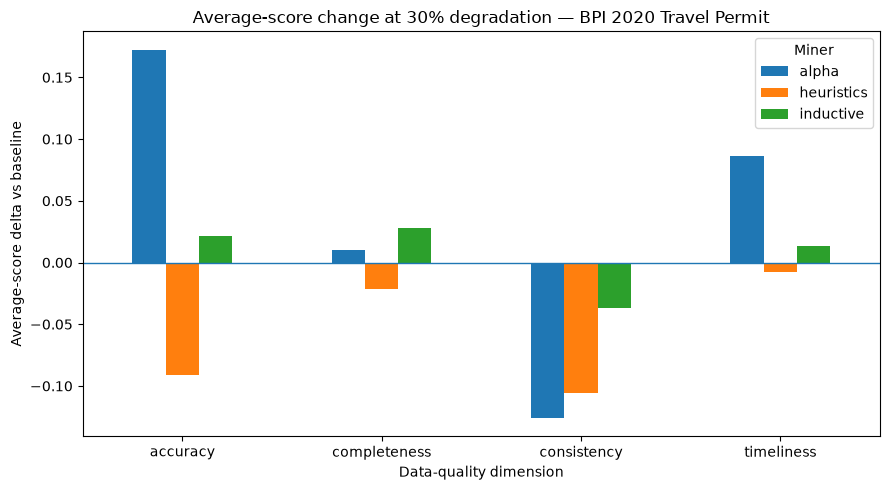

Saved: C:\Users\User\Desktop\projects\thesis-discovery\Data-Quality-Impact-on-Process-Discovery\experiments\process_discovery\results\figures\bpi2020_travel_permit_summary\average_score_delta_30_by_dimension.png


In [7]:
score_plot_df = effects_30.pivot(
    index="dimension", columns="miner", values="average_score_delta"
).reindex(DIMENSIONS)

ax = score_plot_df.plot(kind="bar", figsize=(9, 5))
ax.axhline(0, linewidth=1)
ax.set_title("Average-score change at 30% degradation — BPI 2020 Travel Permit")
ax.set_xlabel("Data-quality dimension")
ax.set_ylabel("Average-score delta vs baseline")
ax.legend(title="Miner")
plt.xticks(rotation=0)
plt.tight_layout()

output_path = FIGURES_DIR / "average_score_delta_30_by_dimension.png"
plt.savefig(output_path, dpi=300)
plt.show()
print("Saved:", output_path)

## 6. Plot 2 — Structural complexity change at 30% degradation

The percentage change in Petri-net arcs is used as one indicator of model complexity. It is interpreted alongside the quality metrics, not as a standalone measure of model quality.

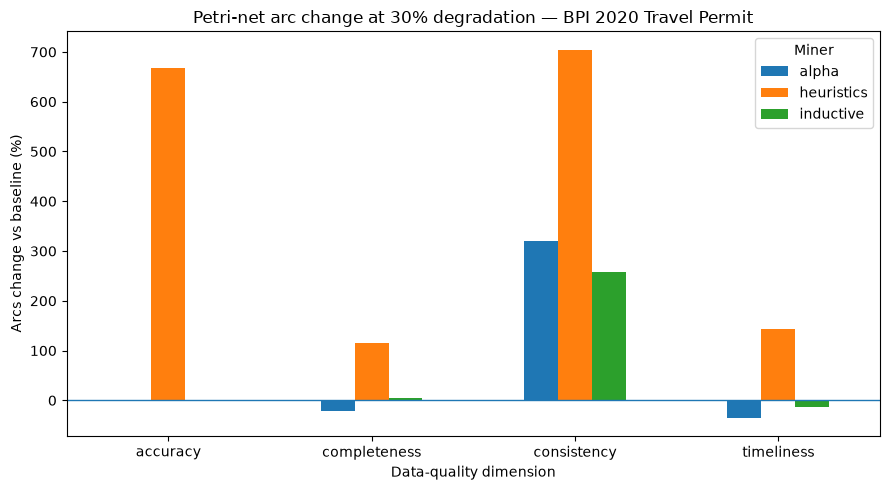

Saved: C:\Users\User\Desktop\projects\thesis-discovery\Data-Quality-Impact-on-Process-Discovery\experiments\process_discovery\results\figures\bpi2020_travel_permit_summary\arcs_pct_change_30_by_dimension.png


In [8]:
arcs_plot_df = effects_30.pivot(
    index="dimension", columns="miner", values="arcs_pct_change"
).reindex(DIMENSIONS)

ax = arcs_plot_df.plot(kind="bar", figsize=(9, 5))
ax.axhline(0, linewidth=1)
ax.set_title("Petri-net arc change at 30% degradation — BPI 2020 Travel Permit")
ax.set_xlabel("Data-quality dimension")
ax.set_ylabel("Arcs change vs baseline (%)")
ax.legend(title="Miner")
plt.xticks(rotation=0)
plt.tight_layout()

output_path = FIGURES_DIR / "arcs_pct_change_30_by_dimension.png"
plt.savefig(output_path, dpi=300)
plt.show()
print("Saved:", output_path)

## 7. Plot 3 — Metric trends across degradation levels

The following plots show how average score changes at 0%, 10%, 20%, and 30% for each degradation dimension. Because the baseline is replicated as level 0 for plotting, it is the same reference value for all four dimensions.

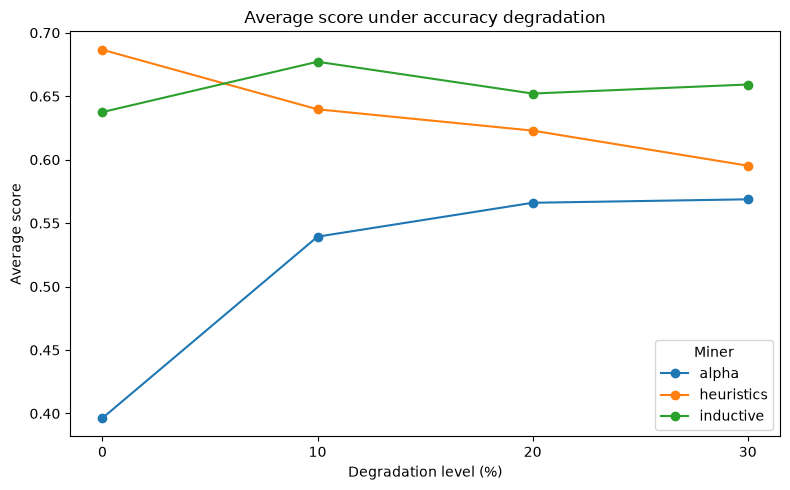

Saved: C:\Users\User\Desktop\projects\thesis-discovery\Data-Quality-Impact-on-Process-Discovery\experiments\process_discovery\results\figures\bpi2020_travel_permit_summary\accuracy_average_score_trend.png


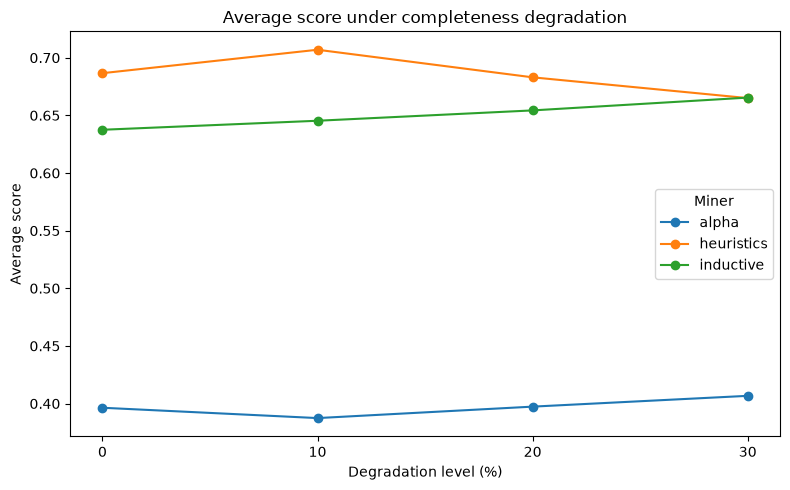

Saved: C:\Users\User\Desktop\projects\thesis-discovery\Data-Quality-Impact-on-Process-Discovery\experiments\process_discovery\results\figures\bpi2020_travel_permit_summary\completeness_average_score_trend.png


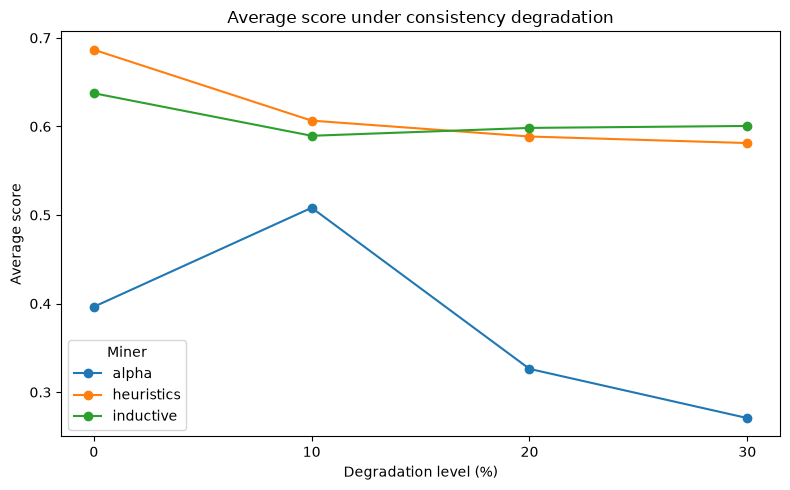

Saved: C:\Users\User\Desktop\projects\thesis-discovery\Data-Quality-Impact-on-Process-Discovery\experiments\process_discovery\results\figures\bpi2020_travel_permit_summary\consistency_average_score_trend.png


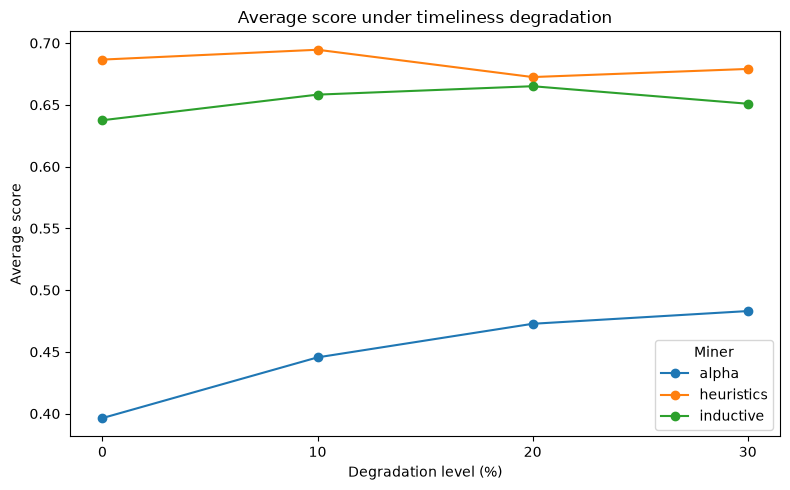

Saved: C:\Users\User\Desktop\projects\thesis-discovery\Data-Quality-Impact-on-Process-Discovery\experiments\process_discovery\results\figures\bpi2020_travel_permit_summary\timeliness_average_score_trend.png


In [9]:
for dimension in DIMENSIONS:
    part = agg[agg["dimension"].eq(dimension)].copy()
    fig, ax = plt.subplots(figsize=(8, 5))

    for miner, miner_part in part.groupby("miner"):
        miner_part = miner_part.sort_values("degradation_level")
        ax.plot(
            miner_part["degradation_level"],
            miner_part["average_score"],
            marker="o",
            label=miner,
        )

    ax.set_title(f"Average score under {dimension} degradation")
    ax.set_xlabel("Degradation level (%)")
    ax.set_ylabel("Average score")
    ax.set_xticks([0, 10, 20, 30])
    ax.legend(title="Miner")
    plt.tight_layout()

    output_path = FIGURES_DIR / f"{dimension}_average_score_trend.png"
    plt.savefig(output_path, dpi=300)
    plt.show()
    print("Saved:", output_path)

## 8. Compact results table

This table collects the mean values at each degradation level for the key quality and structural metrics. It is useful for exporting or consulting results without reading values from the plots.

In [10]:
key_metrics = [
    m for m in [
        "fitness", "precision", "generalization", "simplicity", "average_score",
        "places", "transitions", "arcs", "activities_after"
    ] if m in agg.columns
]

results_table = (
    agg[["dimension", "degradation_level", "miner"] + key_metrics]
    .sort_values(["dimension", "degradation_level", "miner"])
    .reset_index(drop=True)
)

display(results_table.round(3))

csv_output = FIGURES_DIR / "bpi2020_travel_permit_aggregated_results.csv"
results_table.to_csv(csv_output, index=False)
print("Saved:", csv_output)

,dimension,degradation_level,miner,fitness,precision,generalization,simplicity,average_score,places,transitions,arcs,activities_after
0,accuracy,0,alpha,0.448,0.062,0.794,0.281,0.396,66.0,45.000,253.0,45.0
1,accuracy,0,heuristics,0.821,0.875,0.538,0.512,0.687,82.0,153.000,347.0,45.0
2,accuracy,0,inductive,1.000,0.114,0.834,0.602,0.638,103.0,163.000,354.0,45.0
3,accuracy,10,alpha,0.129,0.935,0.883,0.210,0.539,67.6,45.000,334.4,45.0
4,accuracy,10,heuristics,0.791,0.965,0.394,0.408,0.640,246.6,527.800,1335.6,45.0
5,accuracy,10,inductive,0.993,0.276,0.902,0.538,0.677,53.8,100.200,219.6,45.0
6,accuracy,20,alpha,0.128,1.000,0.902,0.234,0.566,50.4,45.000,255.4,45.0
7,accuracy,20,heuristics,0.753,0.964,0.397,0.378,0.623,374.6,733.400,2021.4,45.0
8,accuracy,20,inductive,1.000,0.187,0.910,0.511,0.652,45.2,90.600,200.4,45.0
9,accuracy,30,alpha,0.126,0.991,0.913,0.245,0.569,53.2,45.000,253.4,45.0


Saved: C:\Users\User\Desktop\projects\thesis-discovery\Data-Quality-Impact-on-Process-Discovery\experiments\process_discovery\results\figures\bpi2020_travel_permit_summary\bpi2020_travel_permit_aggregated_results.csv


## 9. Interpretation notes

Use the tables and plots above to formulate conclusions after inspecting the actual output. In particular:

- Compare degradation effects **within each miner**, relative to that miner's baseline.
- Treat failed runs as a limitation and report which conditions failed; do not silently interpret missing metrics as zero.
- Interpret `average_score` together with fitness, precision, generalization, and simplicity.
- Inspect structural measures (places, transitions, arcs, activities) because quality metrics alone may not reveal changes in model complexity.
- The metrics are evaluated on the corresponding input logs. A degraded log can therefore yield a model that scores reasonably on that same degraded log without demonstrating robustness against the original process.
- These are descriptive summaries. If inferential tests are needed, select them based on the experimental design and the repeated-run structure rather than applying a test mechanically.